# Demo: evaluar un LLM que extrae datos de avisos de empleo

Claude (`claude-opus-5-5`) leyó **60 avisos de empleo bolivianos** y llenó 8 campos por aviso
(cargo, ciudad, modalidad, salarios, moneda, experiencia, fecha de cierre), con dos prompts:

- **v1:** un pedido corto con la lista de campos.
- **v2:** la guía de anotación (`ejemplos/guia_anotacion.md`) más un JSON Schema.

**El eval:** los 60 avisos con su **respuesta correcta** escrita a mano (el *golden set*, en
`ejemplos/avisos.jsonl`) más un **calificador en código** (`demo/extraccion.py`) que compara
campo por campo. Las salidas son **reales** (generadas el 29/10/2026 con
`demo/extraer_con_claude.py`); este notebook solo las **califica**: no llama a ninguna API.

## Los tres evals

1. **Formato** — ¿devuelve lo que se pidió? (JSON válido, esquema)
2. **Correctitud contra la referencia** — cada campo comparado con la respuesta correcta,
   con una regla de comparación: exacta, normalizada o difusa
3. **Comparación pareada** — ¿v2 es mejor que v1, o es azar?

## El prompt, tal cual

**v1**, una sola línea:

> "Extrae del aviso de empleo estos campos y responde en JSON: cargo, ciudad, modalidad, salario_min, salario_max, moneda, experiencia_anios, fecha_cierre."

**v2**, la sección "Reglas" de [la guía de anotación](ejemplos/guia_anotacion.md), tal cual
(lo que se le pide a una persona que anota y lo que se le pide al modelo es lo mismo), más un
**JSON Schema** por salidas estructuradas: tipos y vocabulario cerrado (`modalidad` solo puede
ser `presencial`, `remoto` o `hibrido`; `moneda`, `BOB` o `USD`).

In [1]:
import sys
sys.path.append("demo")
import matplotlib.pyplot as plt
from extraccion import CAMPOS, evaluar, leer, todo_bien
from formulas import mcnemar_exacto, wilson

avisos = leer("ejemplos/avisos.jsonl")
n = len(avisos)
V = {v: evaluar(avisos, leer(f"ejemplos/salidas_claude_{v}.jsonl")) for v in ("v1", "v2")}

COLOR = {"v1": "#2a78d6", "v2": "#eb6834"}
NOMBRE = {"v1": "v1 (pedido corto)", "v2": "v2 (guía + esquema)"}
TINTA, TENUE, GRIS = "#374151", "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "text.color": TINTA,
                     "axes.labelcolor": TENUE, "xtick.color": TENUE, "ytick.color": TINTA})

def ejes(ax):
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(GRIS)
    ax.tick_params(length=0)
    ax.set_xlim(0, n * 1.14)
    ax.set_xticks(range(0, n + 1, 10))
    ax.grid(axis="x", color=GRIS, lw=0.8)
    ax.set_axisbelow(True)

def leyenda(ax, **kw):
    ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COLOR[v], markersize=9) for v in ("v1", "v2")],
              labels=[NOMBRE["v1"], NOMBRE["v2"]], frameon=False, fontsize=9, **kw)

def full(v, nivel="normalizada"):
    return sum(todo_bien(f, nivel) for f in V[v])

print(f"{n} avisos x 8 campos, dos prompts.")

60 avisos x 8 campos, dos prompts.


## Una fila del eval: el aviso, su respuesta correcta y lo que devolvió Claude

In [2]:
import json
aviso = avisos[0]
crudo_v1 = {json.loads(l)["id"]: json.loads(l)["salida"] for l in open("ejemplos/salidas_claude_v1.jsonl")}
print(aviso["texto"])
print("\n--- la respuesta correcta (gold) ---")
print(json.dumps(aviso["gold"], ensure_ascii=False, indent=2))
print("\n--- lo que devolvió v1, crudo ---")
print(crudo_v1[aviso["id"]])

Importante empresa de retail busca Analista de Datos en Santa Cruz. Requisitos: 2 años de experiencia en SQL y Power BI. Sueldo: Bs 8.000. Modalidad presencial. Enviar CV hasta el 15 de noviembre.

--- la respuesta correcta (gold) ---
{
  "cargo": "Analista de Datos",
  "ciudad": "Santa Cruz",
  "modalidad": "presencial",
  "salario_min": 8000,
  "salario_max": 8000,
  "moneda": "BOB",
  "experiencia_anios": 2,
  "fecha_cierre": "2026-11-15"
}

--- lo que devolvió v1, crudo ---
```json
{
  "cargo": "Analista de Datos",
  "ciudad": "Santa Cruz",
  "modalidad": "presencial",
  "salario_min": 8000,
  "salario_max": 8000,
  "moneda": "BOB",
  "experiencia_anios": 2,
  "fecha_cierre": "15 de noviembre"
}
```

**Notas:**
- **Salario:** el aviso indica un monto único (Bs 8.000), por lo que se repite como mínimo y máximo. No especifica si es bruto o líquido ni la periodicidad, aunque probablemente sea mensual.
- **Moneda:** "Bs" junto con la ciudad de Santa Cruz sugiere bolivianos (BOB).
- **F

## Eval 1 — Formato: ¿devuelve lo que se pidió?

Antes de preguntar si la respuesta es correcta: ¿es JSON válido?, ¿cumple el esquema?

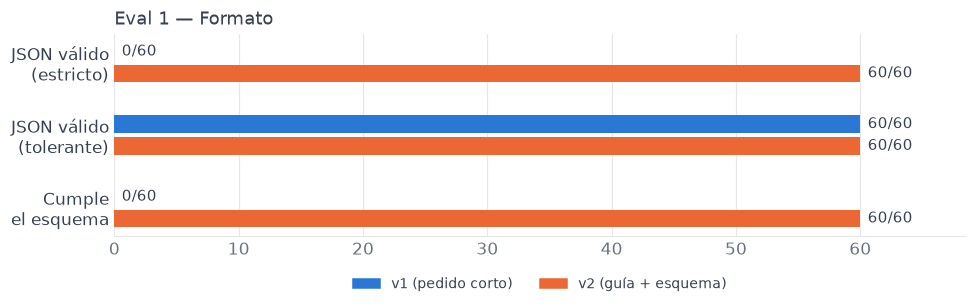

In [3]:
criterios = [("estricto", "JSON válido\n(estricto)"), ("tolerante", "JSON válido\n(tolerante)"),
             ("esquema", "Cumple\nel esquema")]
fig, ax = plt.subplots(figsize=(9, 3))
alto = 0.3
for i, (clave, nombre) in enumerate(criterios):
    y0 = len(criterios) - 1 - i
    for j, v in enumerate(("v1", "v2")):
        k = sum(f[clave] for f in V[v])
        y = y0 + (0.5 - j) * alto
        ax.barh(y, k, height=alto * 0.8, color=COLOR[v], zorder=3)
        ax.text(k + 0.6, y, f"{k}/{n}", va="center", fontsize=10, color=TINTA)
ejes(ax)
ax.set_yticks(range(len(criterios) - 1, -1, -1), [c[1] for c in criterios])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR[v]) for v in ("v1", "v2")],
          labels=[NOMBRE["v1"], NOMBRE["v2"]], loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncols=2, frameon=False, fontsize=9)
ax.set_title("Eval 1 — Formato", loc="left", fontsize=12, color=TINTA)
plt.tight_layout()
plt.show()

v1 no falla por contenido: envuelve el JSON en un bloque de código (estricto
**0/60**) y escribe `"Remoto"` o `"Híbrido (3 días en oficina)"` donde el
esquema pide `remoto`/`hibrido` (esquema **0/60**). El 60/60
de v2 lo garantiza la API con salidas estructuradas.

**El formato se califica aparte del contenido, y va primero.**

## Eval 2 — Correctitud: comparar con la referencia

Cada campo se compara con la respuesta correcta. La **regla de comparación** es parte de la
métrica: exacta (texto idéntico), normalizada (fechas, monedas y mayúsculas unificadas) o
difusa (similitud de texto ≥ 0,8).

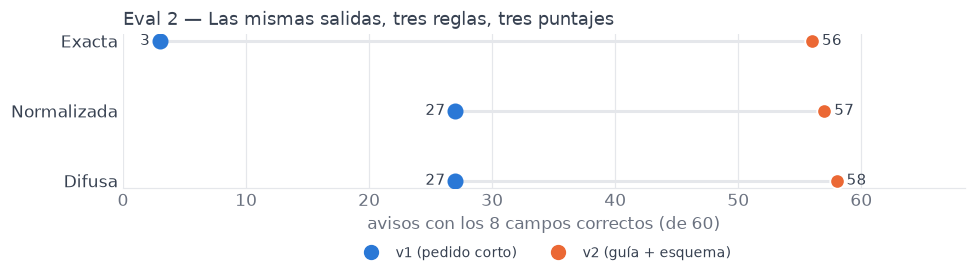

In [4]:
niveles = [("exacta", "Exacta"), ("normalizada", "Normalizada"), ("difusa", "Difusa")]
fig, ax = plt.subplots(figsize=(9, 2.9))
for i, (nivel, nombre) in enumerate(niveles):
    y = len(niveles) - 1 - i
    k1, k2 = full("v1", nivel), full("v2", nivel)
    ax.plot([k1, k2], [y, y], color=GRIS, lw=2, zorder=2)
    ax.scatter([k1], [y], s=90, color=COLOR["v1"], zorder=3)
    ax.scatter([k2], [y], s=90, color=COLOR["v2"], zorder=3, edgecolor="white", lw=1.2)
    ax.text(k1 - 0.8, y, str(k1), ha="right", va="center", fontsize=10)
    ax.text(k2 + 0.8, y, str(k2), ha="left", va="center", fontsize=10)
ejes(ax)
ax.set_yticks(range(len(niveles) - 1, -1, -1), [x[1] for x in niveles])
leyenda(ax, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncols=2)
ax.set_xlabel(f"avisos con los 8 campos correctos (de {n})")
ax.set_title("Eval 2 — Las mismas salidas, tres reglas, tres puntajes", loc="left", fontsize=12, color=TINTA)
plt.tight_layout()
plt.show()

v1 pasa de **3** a **27** de 60 solo por normalizar
fechas, monedas y mayúsculas: extrae bien y escribe distinto.

**La regla de comparación se elige antes de medir.**

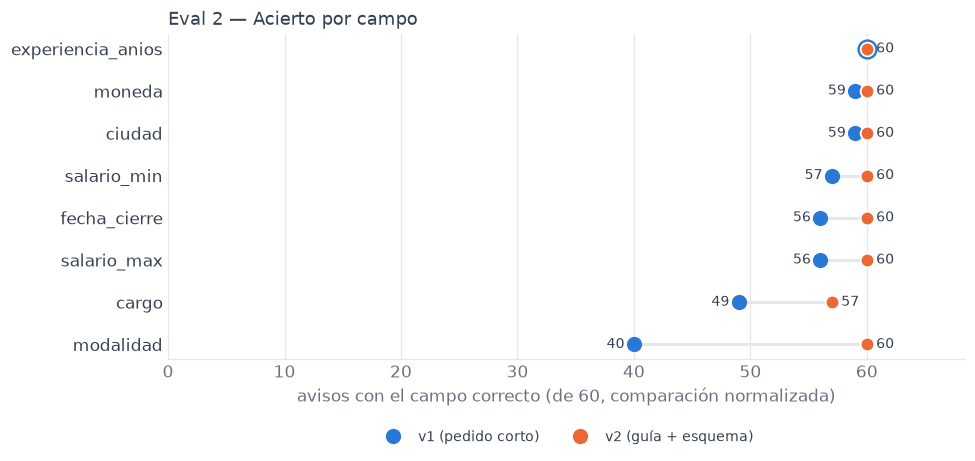

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.4))
orden = sorted(CAMPOS, key=lambda c: sum(f["normalizada"][c] for f in V["v1"]))
for y, c in enumerate(orden):
    k1 = sum(f["normalizada"][c] for f in V["v1"])
    k2 = sum(f["normalizada"][c] for f in V["v2"])
    ax.plot([k1, k2], [y, y], color=GRIS, lw=2, zorder=2)
    ax.scatter([k1], [y], s=150 if k1 == k2 else 80, color=COLOR["v1"], zorder=3)
    ax.scatter([k2], [y], s=80, color=COLOR["v2"], zorder=3, edgecolor="white", lw=1.2)
    if k1 != k2:
        ax.text(k1 - 0.8, y, str(k1), ha="right", va="center", fontsize=9)
    ax.text(k2 + 0.8, y, str(k2), ha="left", va="center", fontsize=9)
ejes(ax)
ax.set_yticks(range(len(orden)), orden)
leyenda(ax, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=2)
ax.set_xlabel(f"avisos con el campo correcto (de {n}, comparación normalizada)")
ax.set_title("Eval 2 — Acierto por campo", loc="left", fontsize=12, color=TINTA)
plt.tight_layout()
plt.show()

El campo que más mueve es **modalidad** (v2 arregla 20, v1 0): la guía
define el vocabulario cerrado y las reglas que v1 no conocía.

## Eval 3 — ¿v2 es mejor? La comparación pareada

El puntaje es una **estimación** con error: la banda es el intervalo de Wilson al 95 %. Y como
los dos prompts respondieron **los mismos avisos**, la prueba correcta es pareada (McNemar):
mira solo los avisos donde uno acierta y el otro no.

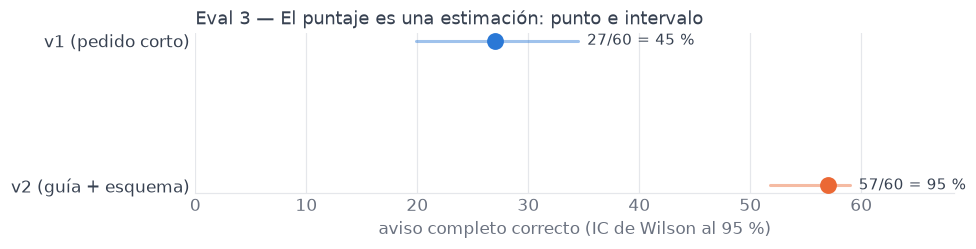

Solo v2 acierta: 30 avisos; solo v1 acierta: 0.
McNemar exacto: p = 0.000000


In [6]:
fig, ax = plt.subplots(figsize=(9, 2.4))
for y, v in enumerate(("v2", "v1")):
    k = full(v)
    lo, hi = wilson(k, n)
    ax.plot([lo * n, hi * n], [y, y], color=COLOR[v], lw=2, alpha=0.45, zorder=2, solid_capstyle="round")
    ax.scatter([k], [y], s=100, color=COLOR[v], zorder=3)
    ax.text(hi * n + 0.8, y, f"{k}/{n} = {100 * k / n:.0f} %", va="center", fontsize=10, color=TINTA)
ejes(ax)
ax.set_yticks([0, 1], [NOMBRE["v2"], NOMBRE["v1"]])
ax.set_xlabel("aviso completo correcto (IC de Wilson al 95 %)")
ax.set_title("Eval 3 — El puntaje es una estimación: punto e intervalo", loc="left", fontsize=12, color=TINTA)
plt.tight_layout()
plt.show()

t1 = [todo_bien(f, "normalizada") for f in V["v1"]]
t2 = [todo_bien(f, "normalizada") for f in V["v2"]]
solo2 = sum(y and not x for x, y in zip(t1, t2))
solo1 = sum(x and not y for x, y in zip(t1, t2))
print(f"Solo v2 acierta: {solo2} avisos; solo v1 acierta: {solo1}.")
print(f"McNemar exacto: p = {mcnemar_exacto(solo2, solo1):.6f}")

v1 **27/60** (45 %), v2 **57/60** (95 %). Solo v2
acierta **30** avisos y solo v1 acierta **0**: McNemar da **p < 0,0001**. No es azar.

## Leer los errores

El puntaje dice **cuánto** falla; leer las salidas dice **por qué**. Los 3 avisos
que v2 falla:

In [7]:
fallan = [f for f in V["v2"] if not todo_bien(f, "normalizada")]
for f in fallan:
    mal = [c for c in CAMPOS if not f["normalizada"][c]]
    for c in mal:
        print(f"Aviso {f['id']} ({c}): esperado {f['gold'][c]!r}, extraído {f['pred'].get(c)!r}")

Aviso 17 (cargo): esperado 'Diseñador Gráfico', extraído 'Diseñador gráfico freelance'
Aviso 21 (cargo): esperado 'Asistente de Investigación', extraído 'Asistente de investigación para tesis'
Aviso 26 (cargo): esperado 'Investigador/a Junior', extraído 'Investigador/a Junior en encuestas de opinión'


Los 3 son el mismo error: el **cargo** con calificativos que la guía dice
recortar. Eso decide qué regla reforzar en la próxima iteración.

**El puntaje dice cuánto falla; leer las salidas dice por qué.**

---

Reporte completo en texto: `python3 demo/extraccion.py` (offline, gratis). Material de la charla
*"¿Cómo saber si una IA responde bien?"* — UMSA, 29/10/2026.
Repo: [github.com/Maxbm19/evals-ia](https://github.com/Maxbm19/evals-ia).